# 02. Refocusing, aperture and perspective

Once a light field is captured, focus is a computation: shift each view in proportion to its position on the lens and average them. Objects whose disparity matches the shift line up and stay sharp, and everything else blurs in the same way a real defocused lens would blur it. The same sum over a subset of views is a digital aperture, and interpolating between views gives a new viewpoint. This notebook refocuses the Lego Knights and the synthetic scene, measures where each plane is sharpest, and then stops down, moves the viewpoint and renders a perspective sequence.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs of textures).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import lf` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
from ipywidgets import interact, FloatSlider
import lf
from lf import io as lfio, refocus, aperture, synthetic, utils

L_lego = lfio.load('lego', downsample=4, angular_crop=9)
L_syn = synthetic.synthetic_light_field(n_views=7, size=128)
print(L_lego)
print(L_syn)

LightField('stanford_lego_knights', angular 9x9, spatial 256x256, 3 ch)
LightField('synthetic', angular 7x7, spatial 128x128, 3 ch)


## Refocusing with alpha

The focus parameter $\alpha$ is the disparity of the plane you want sharp, in pixels per view step. On the synthetic scene the grass is sharp at $\alpha=-1$, the text at $\alpha=0$ and the gravel at $\alpha=1.5$; in between, nothing is sharp.

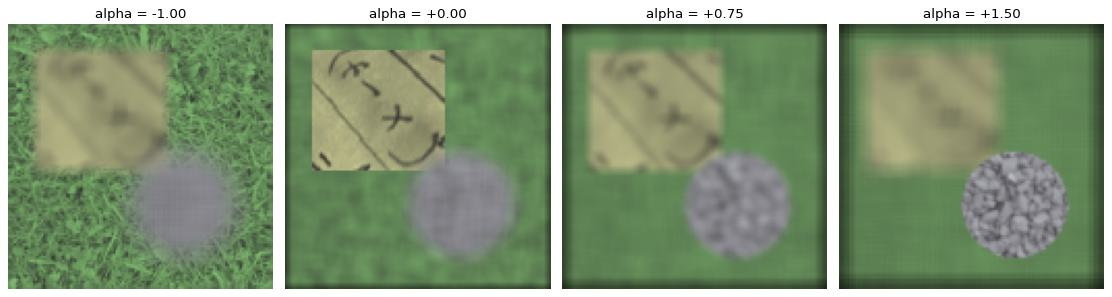

In [2]:
alphas_syn = [-1.0, 0.0, 0.75, 1.5]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, a in zip(axes, alphas_syn):
    ax.imshow(np.clip(refocus.refocus(L_syn, a), 0, 1))
    ax.set_title(f'alpha = {a:+.2f}'); ax.axis('off')
plt.tight_layout()

Each layer comes into focus only at its own disparity, which is why the refocusing parameter doubles as a depth estimate. The image at $\alpha = 0.75$ is blurred everywhere because no layer has that disparity.

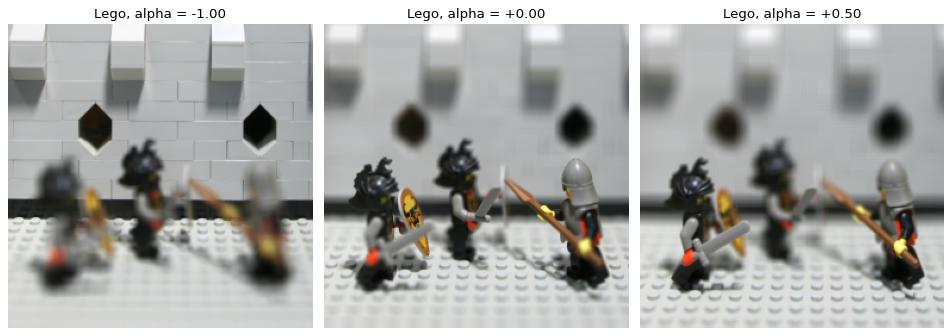

In [3]:
alphas_lego = [-1.0, 0.0, 0.5]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, a in zip(axes, alphas_lego):
    ax.imshow(np.clip(refocus.refocus(L_lego, a), 0, 1))
    ax.set_title(f'Lego, alpha = {a:+.2f}'); ax.axis('off')
plt.tight_layout()

At $\alpha = -1$ the castle wall is sharp and the knights are blurred; at $\alpha$ between 0 and 0.5 the knights come into focus instead. These are the ranges that `refocus.SUGGESTED_ALPHA_RANGE` suggests for this crop.

The cell shows a static preview at the default value first, which is also what a headless run records. In JupyterLab the slider then takes over and refocuses interactively.

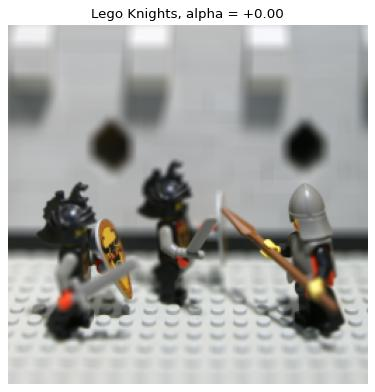

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='alpha', max=1.5, min=-2.0, …

In [4]:
def show_refocus(alpha=0.0):
    img = refocus.refocus(L_lego, alpha)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(f'Lego Knights, alpha = {alpha:+.2f}'); ax.axis('off')
    plt.tight_layout()
    plt.show()

show_refocus(0.0)   # static preview (kept in the saved notebook)
interact(show_refocus, alpha=FloatSlider(min=-2.0, max=1.5, step=0.05, value=0.0,
                                         continuous_update=False, description='alpha'));

## How sharp is each plane?

`sweep_sharpness` refocuses over a range of $\alpha$ and scores a region of interest with the variance of the Laplacian. Plotting the score against $\alpha$ shows the focus peak for each region. We use one region on the text plane and one on the gravel disc of the synthetic scene.

text ROI peaks at alpha   = 0.0
gravel ROI peaks at alpha = 1.5


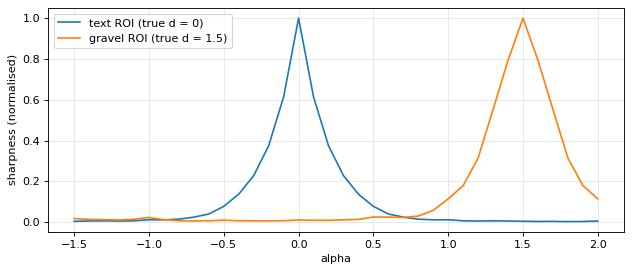

In [5]:
alphas = np.linspace(-1.5, 2.0, 36)
text_roi = (slice(30, 60), slice(30, 60))
gravel_roi = (slice(75, 95), slice(75, 95))
s_text = refocus.sweep_sharpness(L_syn, alphas, roi=text_roi)
s_gravel = refocus.sweep_sharpness(L_syn, alphas, roi=gravel_roi)
print('text ROI peaks at alpha   =', round(float(alphas[np.argmax(s_text)]), 2))
print('gravel ROI peaks at alpha =', round(float(alphas[np.argmax(s_gravel)]), 2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(alphas, s_text / s_text.max(), label='text ROI (true d = 0)')
ax.plot(alphas, s_gravel / s_gravel.max(), label='gravel ROI (true d = 1.5)')
ax.set_xlabel('alpha'); ax.set_ylabel('sharpness (normalised)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()

Each region peaks at its own disparity, so the sweep recovers depth without any calibration. The peaks are slightly broad because a bilinear shift is a weak low-pass filter at fractional $\alpha$.

## Three ways to shift a view

`refocus` supports three shift methods: `subpixel` (bilinear, replicated borders), `integer` (each view rounded to whole pixels) and `fourier` (a phase ramp, exact for band-limited images but periodic at the borders). We compare them at a fractional $\alpha = 0.5$, using `fourier` as the reference and ignoring a 8-pixel border where the boundary models differ.

method      time [ms]   PSNR vs fourier (interior)
subpixel          5.2                         52.5
integer           4.5                         42.5
fourier          26.2                          inf


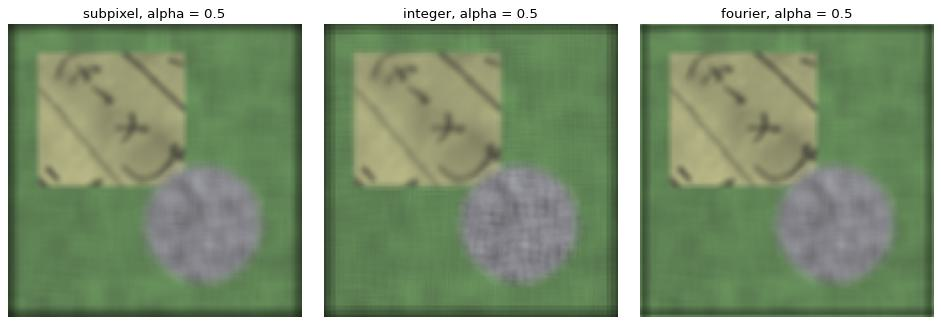

In [6]:
a = 0.5
out, times = {}, {}
for m in ['subpixel', 'integer', 'fourier']:
    t0 = time.perf_counter()
    out[m] = refocus.refocus(L_syn, a, method=m)
    times[m] = 1e3 * (time.perf_counter() - t0)

ref = out['fourier']
print(f"{'method':10s} {'time [ms]':>10s} {'PSNR vs fourier (interior)':>28s}")
for m in out:
    p = utils.psnr(out[m][8:-8, 8:-8], ref[8:-8, 8:-8])
    print(f"{m:10s} {times[m]:10.1f} {p:28.1f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, m in zip(axes, out):
    ax.imshow(np.clip(out[m], 0, 1)); ax.set_title(f'{m}, alpha = {a}'); ax.axis('off')
plt.tight_layout()

The subpixel result is close to the Fourier reference (about 52 dB in the interior), and integer rounding is clearly further off (about 42 dB). Fourier is the most accurate and the slowest of the three, and the borders differ most, where replicated and periodic boundaries disagree.

## A focal stack

Refocusing at a set of $\alpha$ values gives a focal stack. Each frame of the Lego montage is focused on a different depth, so the wall and the knights take turns being sharp.

focal stack shape: (8, 256, 256, 3)


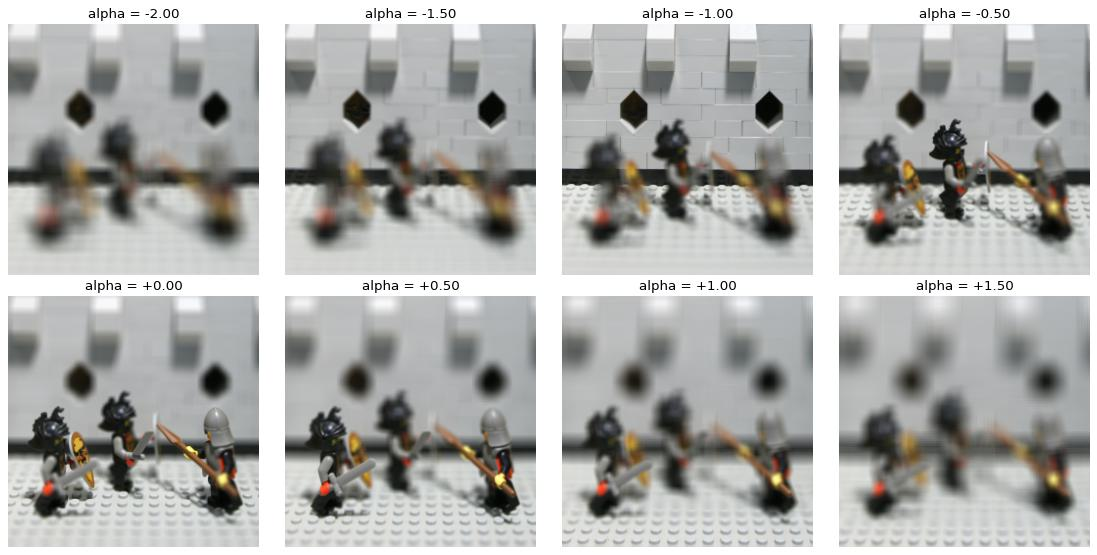

In [7]:
stack_alphas = np.linspace(-2.0, 1.5, 8)
stack = refocus.focal_stack(L_lego, stack_alphas)
print('focal stack shape:', stack.shape)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, a, im in zip(axes.ravel(), stack_alphas, stack):
    ax.imshow(np.clip(im, 0, 1)); ax.set_title(f'alpha = {a:+.2f}'); ax.axis('off')
plt.tight_layout()

The focal stack is the input to the all-in-focus and depth-from-focus methods of notebook 03. Every frame throws away some of the light that the others keep.

## Digital stopping down

`stop_down` refocuses using only the views inside a disc of a given radius, which is an aperture you choose after the exposure. `effective_f_number` converts that radius to the f-number of an equivalent physical camera, using the digital refocusing theorem with a main lens of f/4 and 9 pixels per micro-lens. The panels below are all focused on the castle wall at $\alpha = -1$.

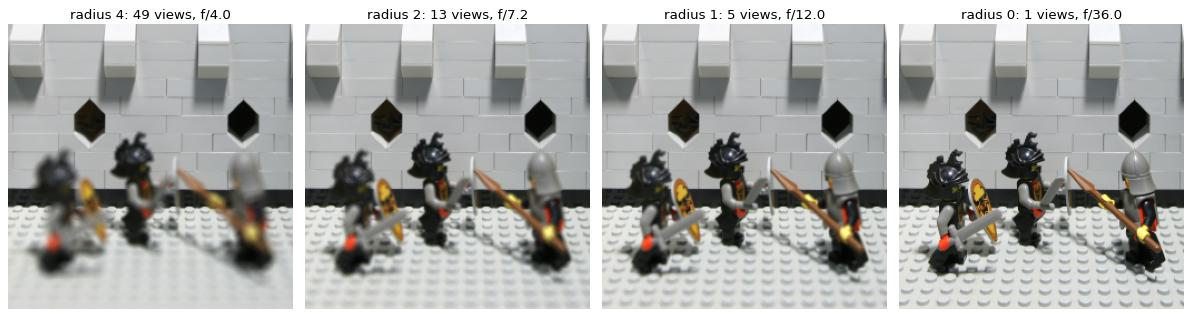

In [8]:
radii = [4, 2, 1, 0]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, r in zip(axes, radii):
    img = aperture.stop_down(L_lego, radius=r, alpha=-1.0)
    n_views = int(aperture.aperture_mask(9, 9, 'circle', r).sum())
    fnum = aperture.effective_f_number(4.0, 9, r)
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(f'radius {r}: {n_views} views, f/{fnum:.1f}')
    ax.axis('off')
plt.tight_layout()

A smaller radius gives a larger depth of field: at radius 0 one view is a pinhole image and nothing is blurred by averaging. The price is light, which is free in this noise-free data but costs SNR on a real sensor.

## Fractional viewpoints

`synthesize_view` interpolates between the four nearest views at a fractional position $(u, v)$. The midpoint between four views is a plausible new viewpoint for distant things, but nearby things with larger disparity appear twice.

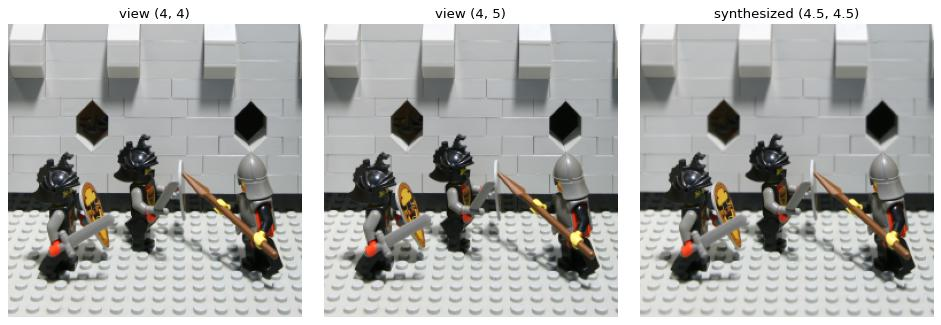

In [9]:
u0, v0 = L_lego.center
panels = [(f'view ({u0}, {v0})', L_lego.view(u0, v0)),
          (f'view ({u0}, {v0 + 1})', L_lego.view(u0, v0 + 1)),
          (f'synthesized ({u0 + 0.5}, {v0 + 0.5})', aperture.synthesize_view(L_lego, u0 + 0.5, v0 + 0.5))]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, img) in zip(axes, panels):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(title); ax.axis('off')
plt.tight_layout()

The synthesized midpoint is a plausible blend of its neighbours at this small step. Doubled edges appear when disparities are larger than about a pixel, and avoiding them needs a depth map to warp each neighbour before blending.

## Moving the observer

`perspective_sequence` walks the viewpoint around a circle inside the aperture. The strip below shows eight frames of that path; playing the full 24-frame sequence gives a parallax animation.

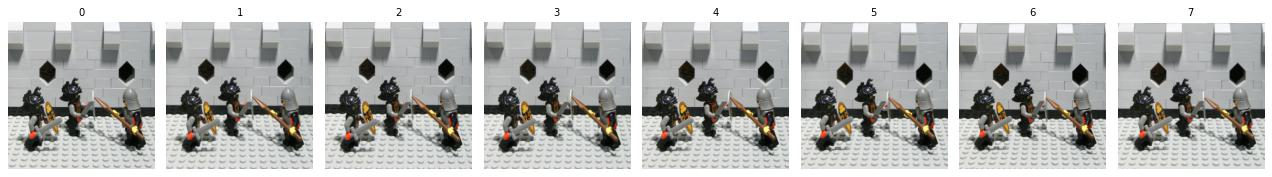

In [10]:
frames = aperture.perspective_sequence(L_lego, path='circle', n=8)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.8))
for k, (ax, f) in enumerate(zip(axes, frames)):
    ax.imshow(np.clip(f, 0, 1)); ax.set_title(f'{k}', fontsize=9); ax.axis('off')
plt.tight_layout()

The background shifts relative to the knights from frame to frame, and that relative motion is the parallax. The sequence is closed, so it loops cleanly.

As before, a static preview at the default viewpoint is shown first, and the sliders then move the viewpoint in JupyterLab.

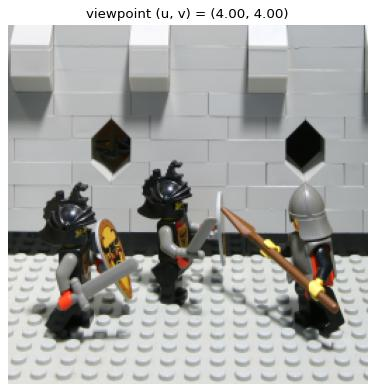

interactive(children=(FloatSlider(value=4.0, continuous_update=False, description='u', max=8.0), FloatSlider(v…

In [11]:
def show_viewpoint(u=4.0, v=4.0):
    img = aperture.synthesize_view(L_lego, u, v)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(f'viewpoint (u, v) = ({u:.2f}, {v:.2f})'); ax.axis('off')
    plt.tight_layout()
    plt.show()

show_viewpoint(4.0, 4.0)   # static preview (kept in the saved notebook)
interact(show_viewpoint,
         u=FloatSlider(min=0.0, max=8.0, step=0.1, value=4.0, continuous_update=False),
         v=FloatSlider(min=0.0, max=8.0, step=0.1, value=4.0, continuous_update=False));

## Where to go next

Read [docs/03_refocusing.md](../docs/03_refocusing.md) for the shift-and-add derivation and the Fourier and integer variants, [docs/04_aperture_dof.md](../docs/04_aperture_dof.md) for the digital refocusing theorem, and [docs/05_perspective_shift.md](../docs/05_perspective_shift.md) for view synthesis. Notebook 03 uses the focal stack to estimate depth and to build an all-in-focus image. The matching tabs in the Streamlit explorer (`streamlit run app/streamlit_app.py`) expose the same sliders.